In [ ]:
## 2026.06.13 using SeededNTM env
##            Copy from Xenium_lung/Data_process_visual_xenium_4.ipynb
##            See the HE image
## 2026.06.18 Clean code, and then add ‘Michael_data_transfer/s4769/HE/s4769_he_mapping_updated_Visium.xlsx’
##            - 21 available, actually 38 aligned HE images, save cell type at HE/nwn-95916_aligned_d1ec33a2/figures/
##            - FinalLiv-27_c001_v001_r001_reg005_celltype_on_HE.jpg
##            - nwn-95916_aligned_d1ec33a2.tif
## 2026.08.10  


In [2]:
# cd /home/lingyu/ssd2/Python/Hist2Pheno
# bash code/Xenium_lung/demo_VUILD107MA.sh
# bash code/Xenium_lung/demo_VUILD102LA.sh
# bash code/Xenium_lung/demo_VUILD96LA.sh

In [1]:
## for AI edit
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

## Add the code directory to Python path
path = '/home/lingyu/ssd2/Python/'
import os
os.chdir(f'{path}Hist2Pheno/data/CODEX/HCC/')
!pwd

import sys
import importlib
import pandas as pd
from pathlib import Path

_xenium_dir = Path("/home/lingyu/ssd2/Python/Hist2Pheno/code/Xenium_lung")
_codex_dir = Path("/home/lingyu/ssd2/Python/Hist2Pheno/code/CODEX_hcc")
for _d in (_xenium_dir, _codex_dir):
    if str(_d) not in sys.path:
        sys.path.insert(0, str(_d))

# from plot_spatial_he_labels import plot_spatial_he_maps, DEFAULT_FIGURES_DIR

import s4769_img_cell_mapping
importlib.reload(s4769_img_cell_mapping)
from s4769_img_cell_mapping import (
    DEFAULT_CODEX_HCC_DIR,
    S4769_SAMPLE,
    load_visium_he_mapping,
    load_codex_he_alignment,
    export_he_zarr_to_tif,
    export_aligned_he_zarrs_to_tif,
    export_aligned_codex_celltypes_to_jpg,
    summarize_visium_he_mapping,
    summarize_codex_he_alignment,
    load_he_rgb,
    plot_he_overview,
    load_cells_by_acq,
    summarize_acquisitions,
    plot_all_acq_spatial,
    plot_celltype_jpg,
    show_saved_jpg,
    preview_aligned_celltype_jpgs,
    export_he_celltype_png,
    plot_all_visium_on_he,
    load_visium_for_acq,
)

CODEX_hcc_dir = str(DEFAULT_CODEX_HCC_DIR)
print("s4769_img_cell_mapping loaded from:", s4769_img_cell_mapping.__file__)


/nobackup2/users/lingyu/Python/Hist2Pheno/data/CODEX/HCC
s4769_img_cell_mapping loaded from: /home/lingyu/ssd2/Python/Hist2Pheno/code/CODEX_hcc/s4769_img_cell_mapping.py


### Load HE

HE nwn-95916_aligned_d1ec33a2: shape=(3, 5431, 7236), dtype=uint8
HE RGB array: (5431, 7236, 3), value range [0, 255]
Saved: /nobackup2/users/lingyu/Python/Hist2Pheno/data/CODEX/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_d1ec33a2/figures/he_img_overview.jpg


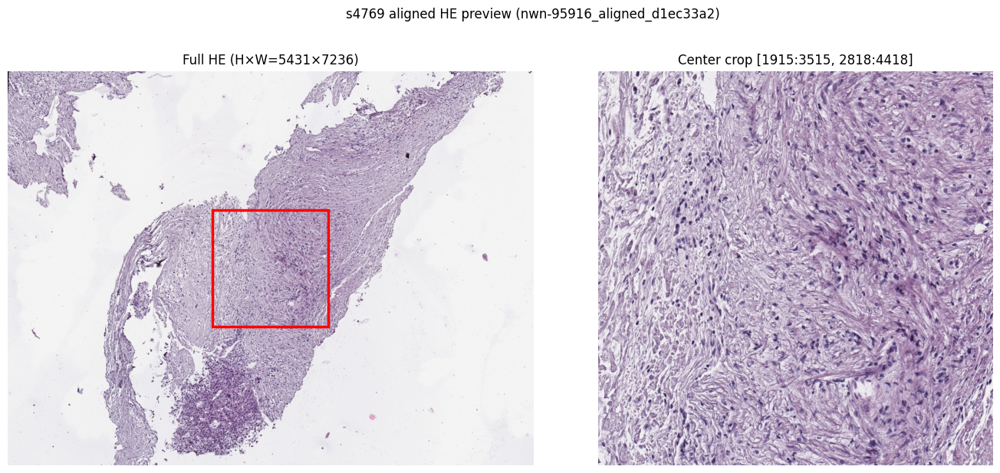

In [3]:
# reg005 aligned HE (reg006 uses nwn-95916_aligned_b16cf712)
HE_PREVIEW_KEYS = [
    'nwn-95916_aligned_d1ec33a2',   # reg005
    # 'nwn-95916_aligned_b16cf712',   # reg006
]

for he_key in HE_PREVIEW_KEYS:
    he_rgb, _ = plot_he_overview(he_key, base_dir=CODEX_hcc_dir)


### Load HE ↔ CODEX aligment (ALIGNED=Y only)
Load HE ↔ CODEX ↔ Visium mapping (Visium=Y only)


In [3]:
## Visium subset (21 rows): Visium=='Y' — required for Visium spot loading
mapping_df = load_visium_he_mapping(base_dir=CODEX_hcc_dir)
# summarize_visium_he_mapping(mapping_df, base_dir=CODEX_hcc_dir)

## CODEX↔HE alignment (38 rows): ALIGNED=='Y' — use for CODEX cell overlay on HE
alignment_df = load_codex_he_alignment(base_dir=CODEX_hcc_dir)
summarize_codex_he_alignment(alignment_df, base_dir=CODEX_hcc_dir)

## Example: load CODEX cells for selected regions
PRIMARY_ACQ_ID = 'FinalLiv-27_c001_v001_r001_reg005'
ACQ_IDS_ALSO_VIEW = []  # e.g. ['FinalLiv-27_c001_v001_r001_reg006']

cells_by_acq = load_cells_by_acq(
    PRIMARY_ACQ_ID, ACQ_IDS_ALSO_VIEW or None, base_dir=CODEX_hcc_dir,
)
cells = cells_by_acq[PRIMARY_ACQ_ID]
summarize_acquisitions(cells_by_acq, alignment_df)

CODEX↔HE alignment rows: 38

=== FinalLiv-27_c001_v001_r001_reg001 | 70_2 ===
  MATCHED_HE='awy-98938_aligned_0d535a74'  exists=True
  ALIGNED=Y  Annotation=True  Visium=False  CSV='070_2_tissue_positions_list.csv'  exists=False

=== FinalLiv-27_c001_v001_r001_reg002 | 70_3 ===
  MATCHED_HE='awy-98938_aligned_8ded610e'  exists=True
  ALIGNED=Y  Annotation=True  Visium=False  CSV='070_3_tissue_positions_list.csv'  exists=False

=== FinalLiv-27_c001_v001_r001_reg003 | 70_4 ===
  MATCHED_HE='awy-98938_aligned_a5afeef9'  exists=True
  ALIGNED=Y  Annotation=True  Visium=False  CSV='070_4_tissue_positions_list.csv'  exists=False

=== FinalLiv-27_c001_v001_r001_reg004 | 70_5 ===
  MATCHED_HE='awy-98938_aligned_59f27598'  exists=True
  ALIGNED=Y  Annotation=True  Visium=False  CSV='070_5_tissue_positions_list.csv'  exists=False

=== FinalLiv-27_c001_v001_r001_reg005 | 71_2 ===
  MATCHED_HE='nwn-95916_aligned_d1ec33a2'  exists=True
  ALIGNED=Y  Annotation=True  Visium=True  CSV='071_2_tissue_po

In [ ]:
## Export ALIGNED HE Zarr → TIFF (38 datasets)
## Each HE saved as: s4769/HE/{MATCHED_HE}/figures/{MATCHED_HE}.tif

# he_tif_paths = export_aligned_he_zarrs_to_tif(
#     alignment_df,
#     base_dir=CODEX_hcc_dir,
#     skip_if_exists=True,   # set overwrite=True to re-export
# )
# print(f"Done: {len(he_tif_paths)} TIFF files")
# he_tif_paths[:3]

Exporting 38 HE Zarr → TIFF
SKIP (exists): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_0d535a74/figures/awy-98938_aligned_0d535a74.tif
Saved: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_8ded610e/figures/awy-98938_aligned_8ded610e.tif  shape=(5434, 7310, 3) dtype=float64
Saved: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_a5afeef9/figures/awy-98938_aligned_a5afeef9.tif  shape=(5434, 7310, 3) dtype=float64
Saved: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_59f27598/figures/awy-98938_aligned_59f27598.tif  shape=(5402, 7310, 3) dtype=float64
SKIP (exists): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_d1ec33a2/figures/nwn-95916_aligned_d1ec33a2.tif
SKIP (exists): /home/lingyu/ssd2/Python/Collaborate/esccAI/d

[PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_0d535a74/figures/awy-98938_aligned_0d535a74.tif'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_8ded610e/figures/awy-98938_aligned_8ded610e.tif'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_a5afeef9/figures/awy-98938_aligned_a5afeef9.tif')]

In [6]:
# alignment_df
cells_by_acq

{'FinalLiv-27_c001_v001_r001_reg005':       CELL_ID  x_pix  y_pix  VALUE             celltype
 0           1   6624      4      3          Fibroblasts
 1           2    627      5     12              B cells
 2           3    130      4      7          CD4 T cells
 3           4    302      6      3          Fibroblasts
 4           5   1229      6      7          CD4 T cells
 ...       ...    ...    ...    ...                  ...
 8691     8692   1908   5383      3          Fibroblasts
 8692     8693   1810   5396      6  Macrophages M2-like
 8693     8694   2045   5415     11   Epithelium (INOS-)
 8694     8695   1759   5420      6  Macrophages M2-like
 8695     8696   1787   5421     13                INFg+
 
 [8696 rows x 5 columns]}

In [ ]:
## CODEX cell types on MATCHED_HE → JPG (38 datasets)
# Saved as: s4769/HE/{MATCHED_HE}/figures/{CODEX_ACQUISITION_ID}_celltype_on_HE.jpg   [No]
# e.g. .../nwn-95916_aligned_d1ec33a2/figures/FinalLiv-27_c001_v001_r001_reg005_celltype_on_HE.jpg   [Yes]

# celltype_jpg_paths = export_aligned_codex_celltypes_to_jpg(
#     alignment_df,
#     base_dir=CODEX_hcc_dir,
#     skip_if_exists=True,   # set overwrite=True to re-export
#     show=False,
# )
# print(f"Done: {len(celltype_jpg_paths)} JPG files")
# celltype_jpg_paths[:3]


Exporting 38 CODEX cell-type maps → JPG
SKIP (exists): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_0d535a74/figures/FinalLiv-27_c001_v001_r001_reg001_celltype_on_HE.jpg


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


Saved: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_8ded610e/figures/FinalLiv-27_c001_v001_r001_reg002_celltype_on_HE.jpg


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


Saved: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_a5afeef9/figures/FinalLiv-27_c001_v001_r001_reg003_celltype_on_HE.jpg


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [3.0..255.0].


In [ ]:
export_he_celltype_png("uzr-70552_aligned_aab73d87", alignment_df, base_dir=CODEX_hcc_dir, dpi=300, show=True, formats=("png", "pdf"))

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_0d535a74/figures/FinalLiv-27_c001_v001_r001_reg001_celltype_on_HE.jpg


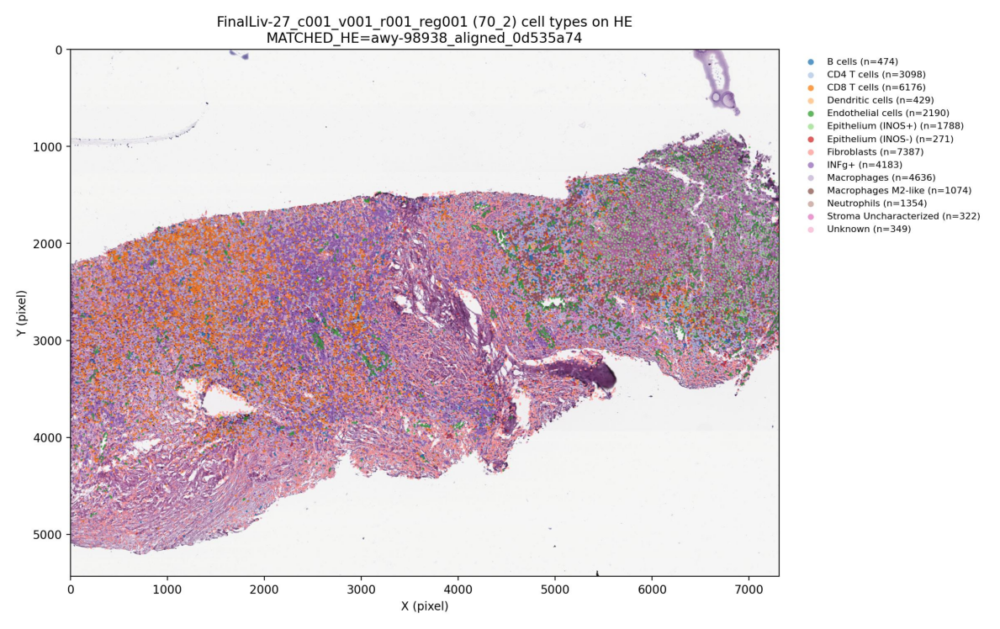

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_8ded610e/figures/FinalLiv-27_c001_v001_r001_reg002_celltype_on_HE.jpg


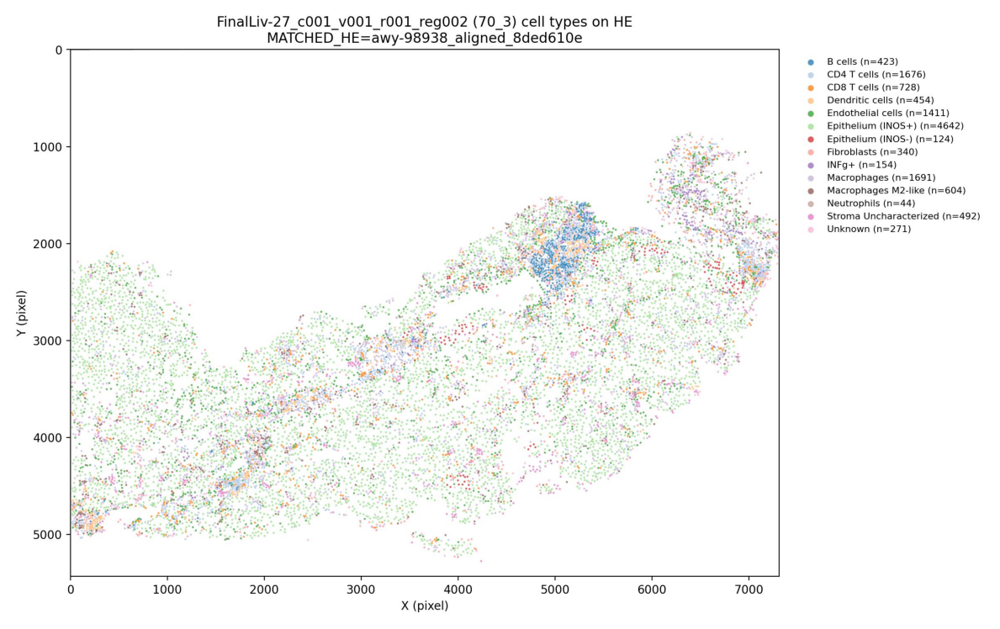

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_a5afeef9/figures/FinalLiv-27_c001_v001_r001_reg003_celltype_on_HE.jpg


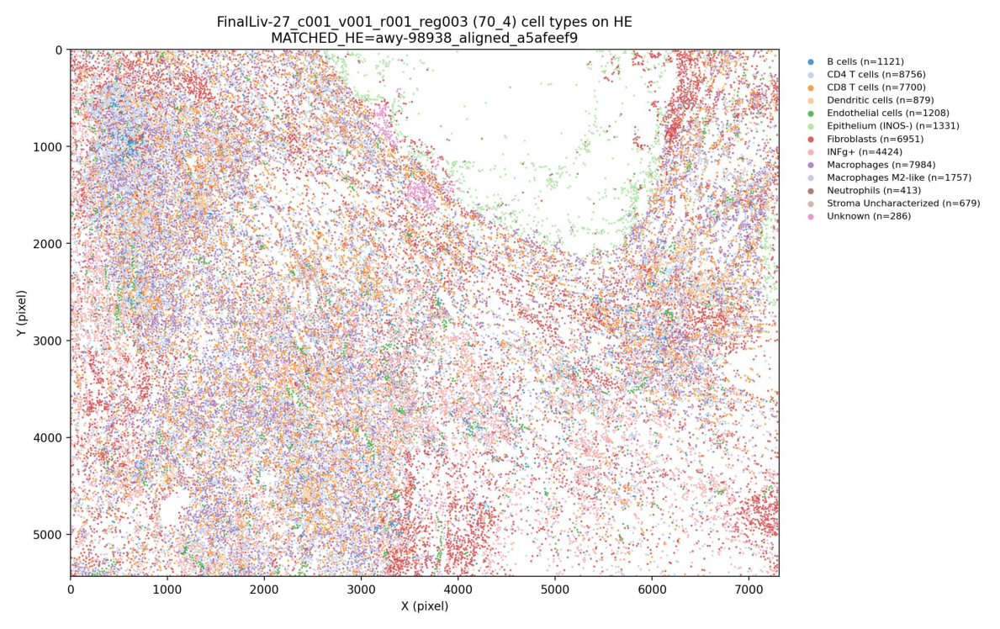

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_59f27598/figures/FinalLiv-27_c001_v001_r001_reg004_celltype_on_HE.jpg


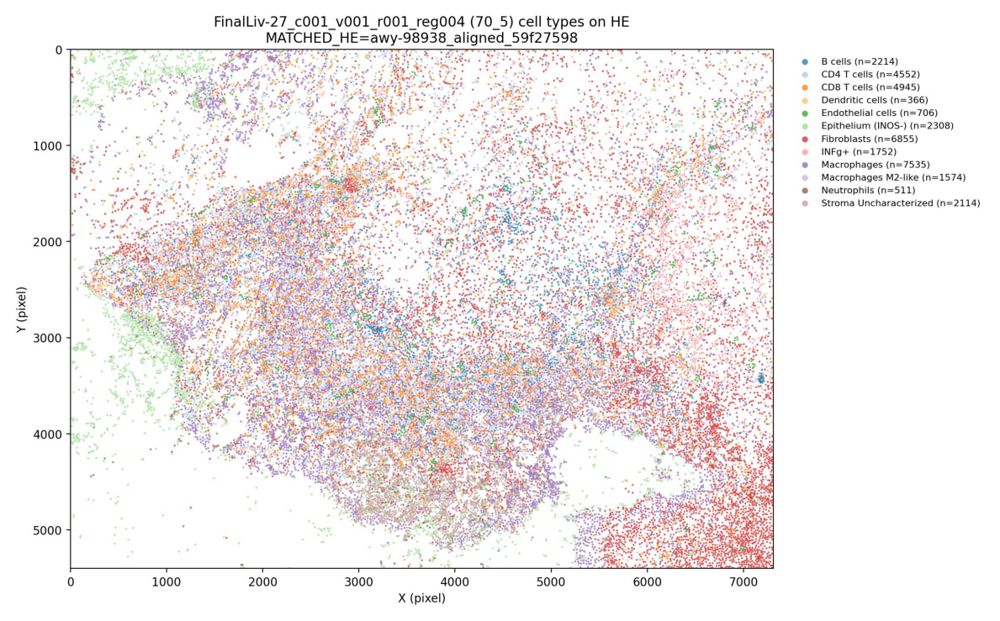

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_d1ec33a2/figures/FinalLiv-27_c001_v001_r001_reg005_celltype_on_HE.jpg


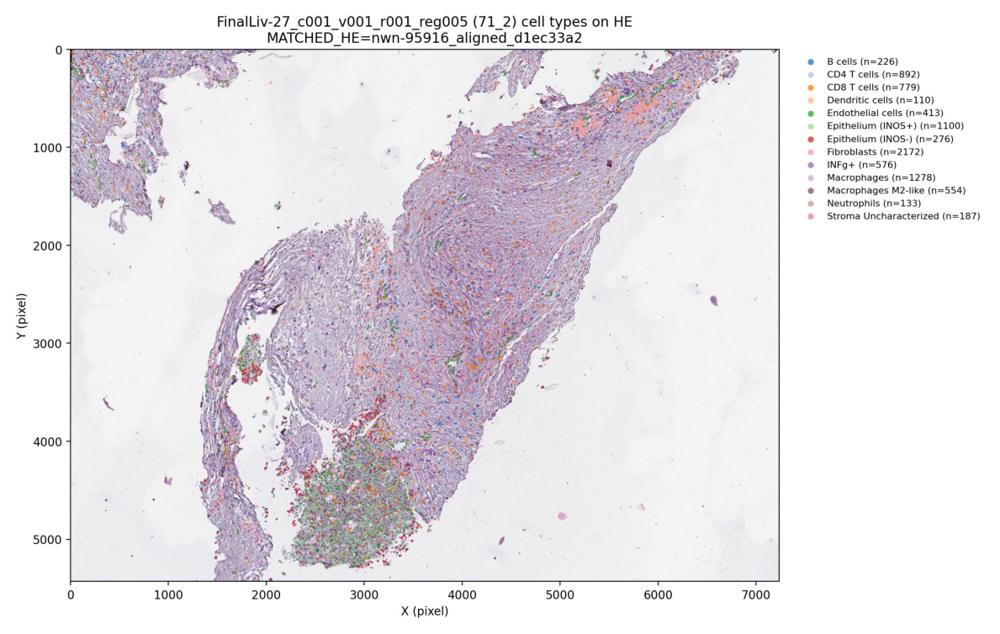

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_b16cf712/figures/FinalLiv-27_c001_v001_r001_reg006_celltype_on_HE.jpg


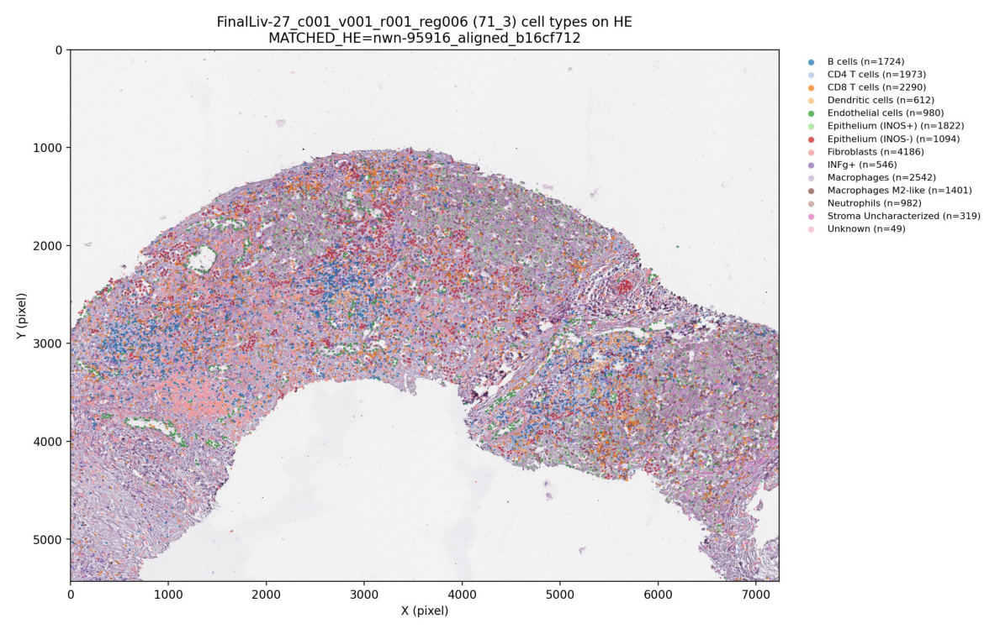

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_459f2ffd/figures/FinalLiv-27_c001_v001_r001_reg007_celltype_on_HE.jpg


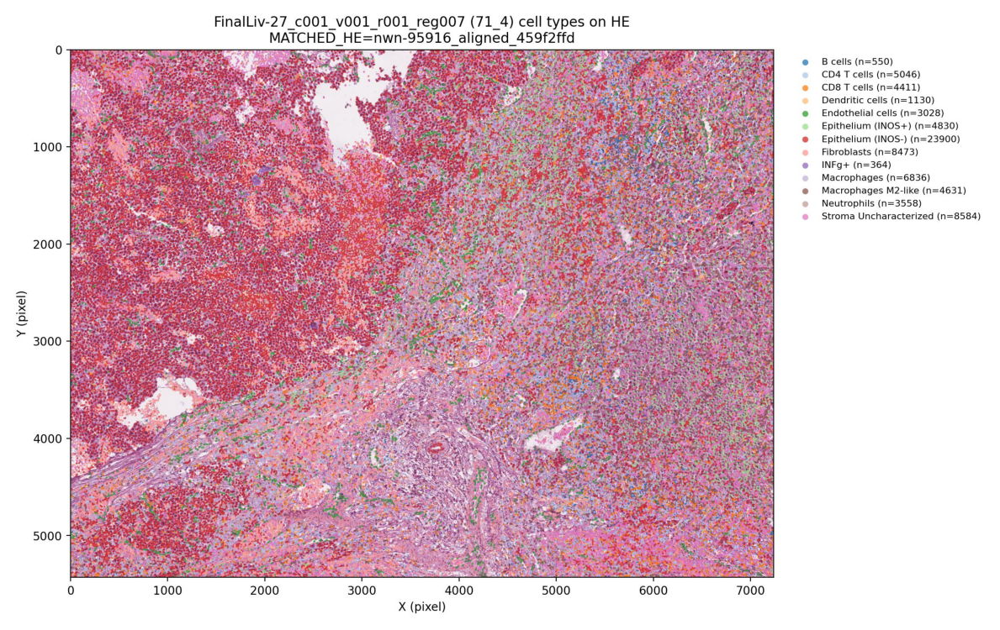

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_737dafc9/figures/FinalLiv-27_c001_v001_r001_reg008_celltype_on_HE.jpg


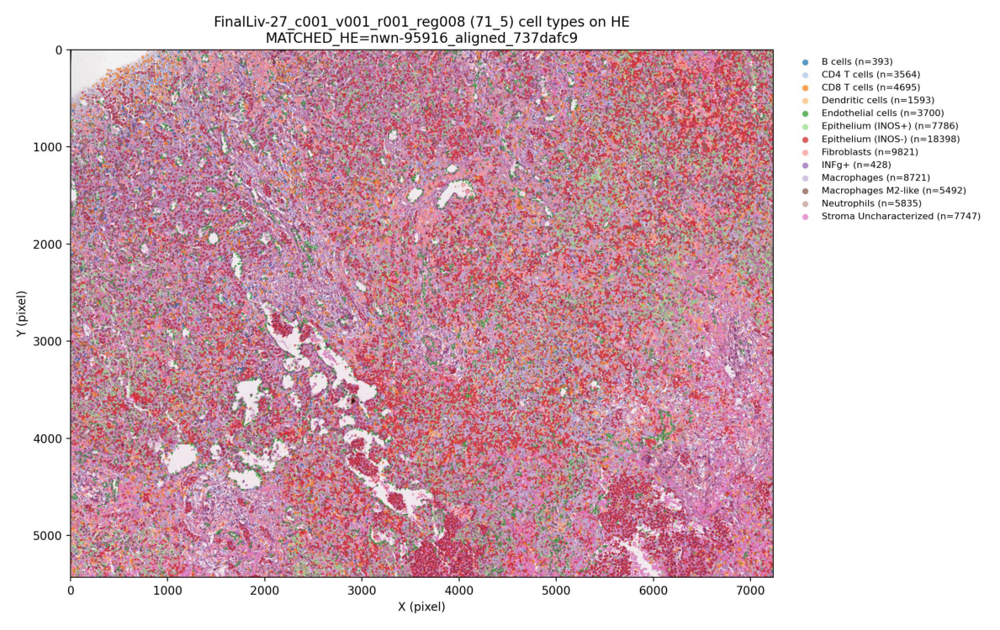

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/dpn-56105_aligned_b32cf147/figures/FinalLiv-27_c001_v001_r001_reg009_celltype_on_HE.jpg


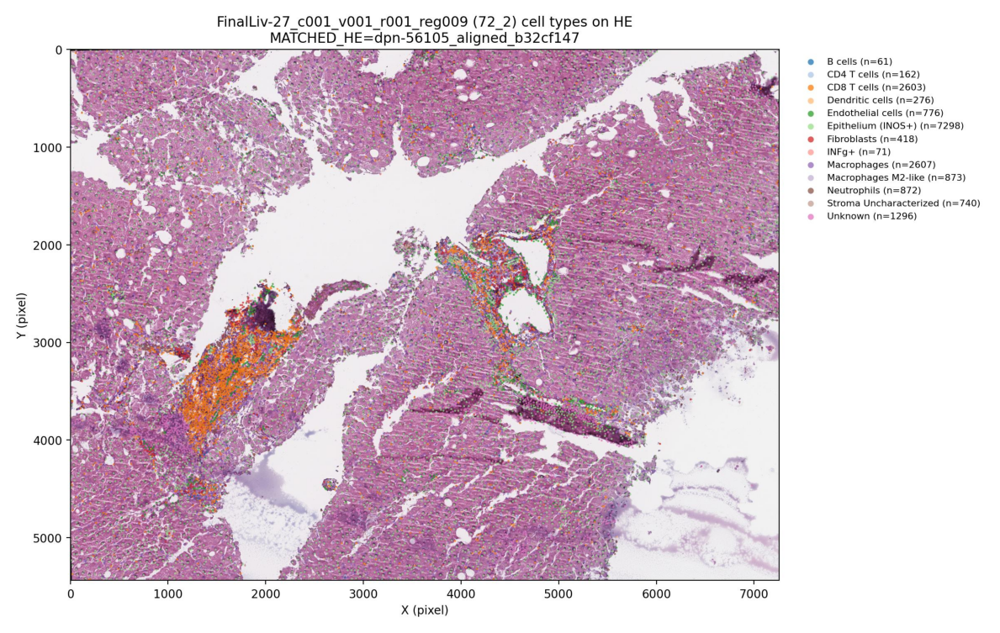

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/dpn-56105_aligned_d24763ad/figures/FinalLiv-27_c001_v001_r001_reg010_celltype_on_HE.jpg


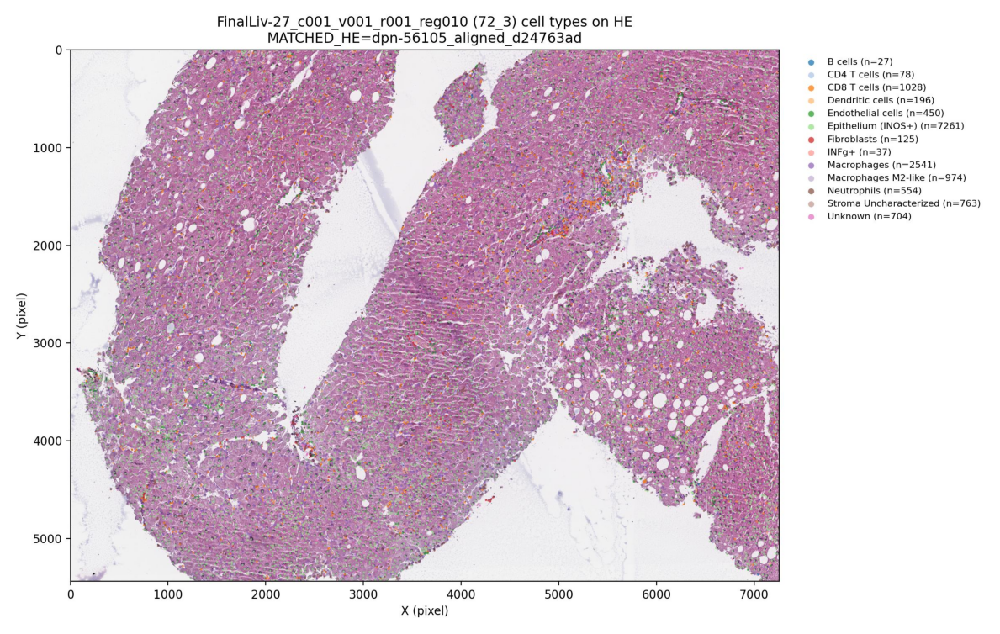

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/dpn-56105_aligned_85543451/figures/FinalLiv-27_c001_v001_r001_reg011_celltype_on_HE.jpg


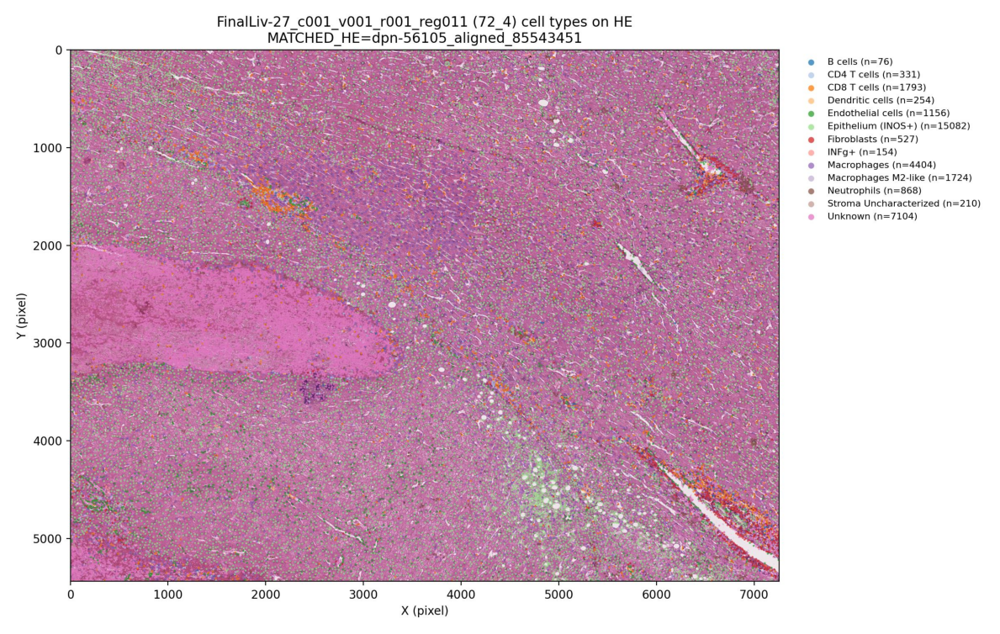

SKIP (no JPG): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/dpn-56105_aligned_93258926/figures/FinalLiv-27_c001_v001_r001_reg012_celltype_on_HE.jpg
Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/kqr-83230_aligned_5b50bc37/figures/FinalLiv-27_c001_v001_r001_reg013_celltype_on_HE.jpg


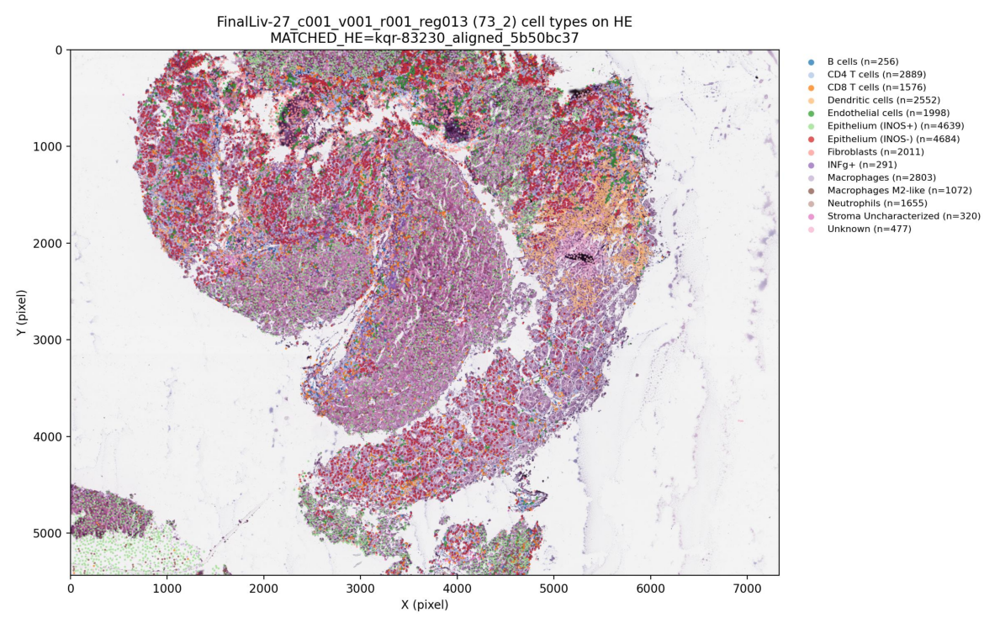

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/kqr-83230_aligned_6f5021e3/figures/FinalLiv-27_c001_v001_r001_reg014_celltype_on_HE.jpg


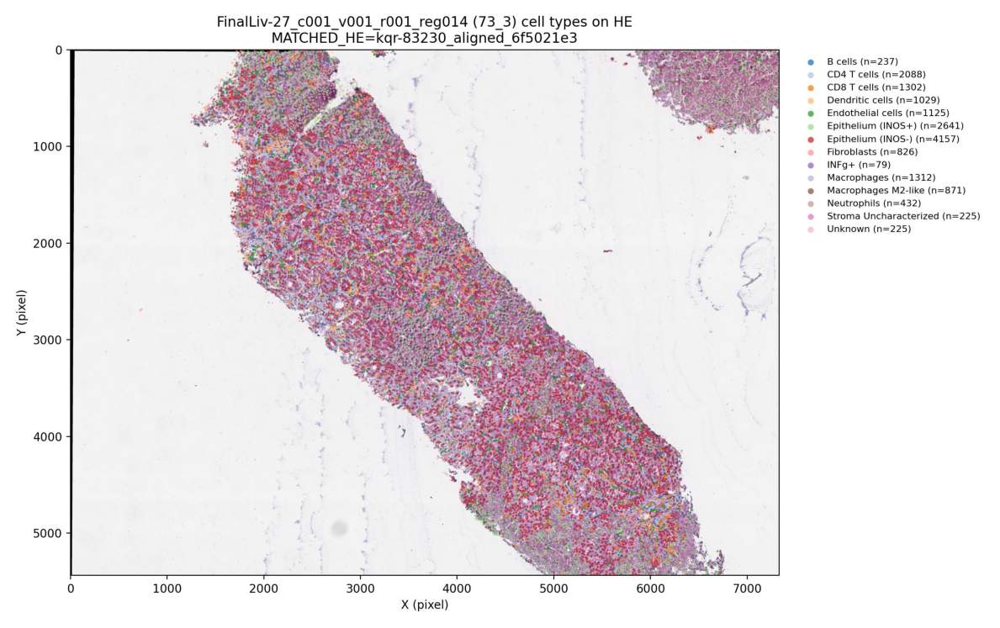

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/kqr-83230_aligned_3bba12d6/figures/FinalLiv-27_c001_v001_r001_reg015_celltype_on_HE.jpg


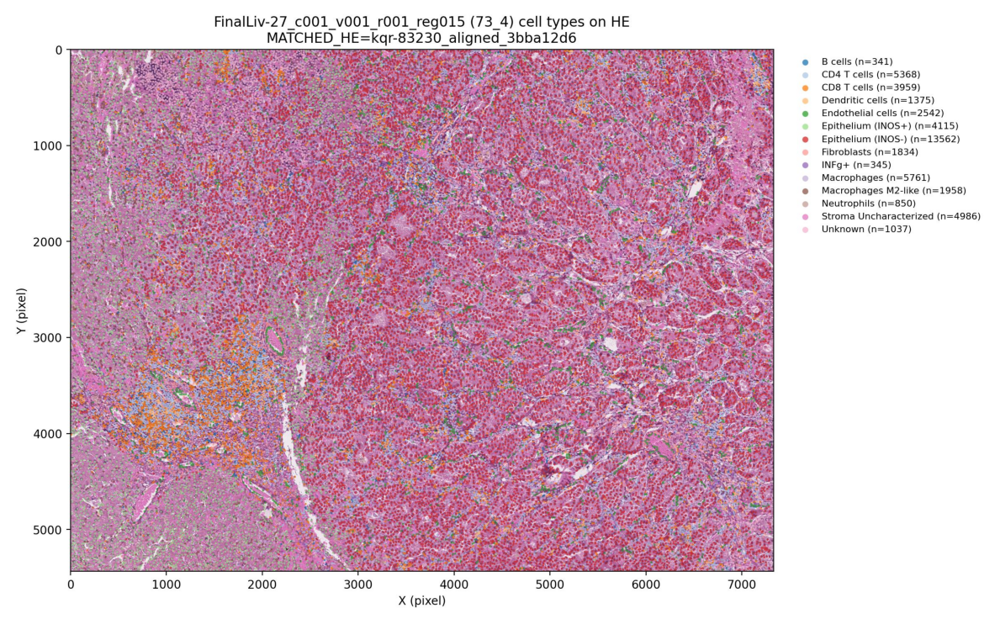

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/kqr-83230_aligned_b24a3fb5/figures/FinalLiv-27_c001_v001_r001_reg016_celltype_on_HE.jpg


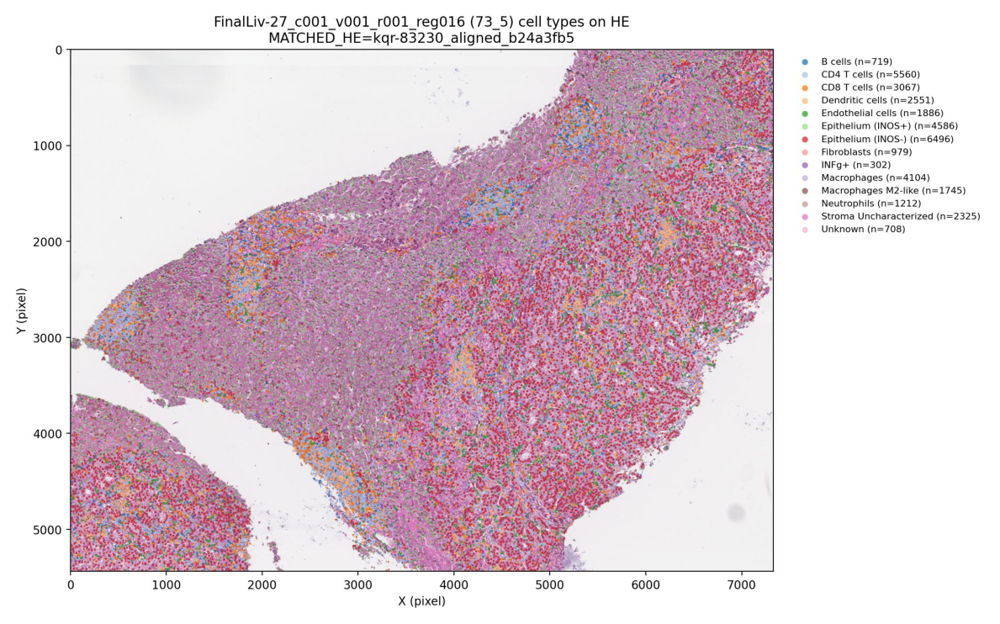

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/fcu-91631_aligned_7ffa2d5a/figures/FinalLiv-27_c001_v001_r001_reg017_celltype_on_HE.jpg


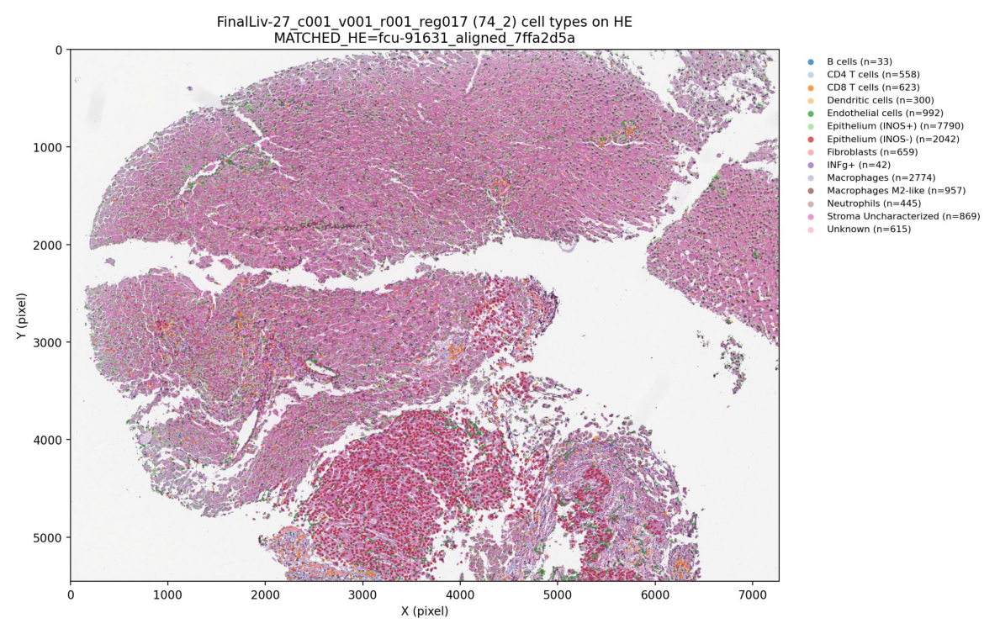

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/fcu-91631_aligned_2e321bd1/figures/FinalLiv-27_c001_v001_r001_reg018_celltype_on_HE.jpg


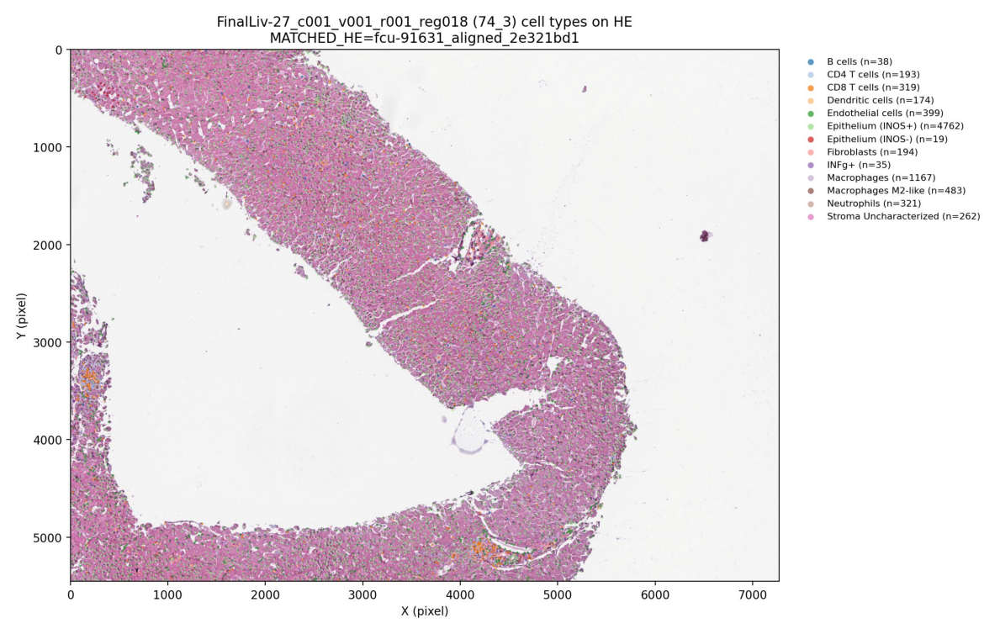

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/fcu-91631_aligned_4722207f/figures/FinalLiv-27_c001_v001_r001_reg019_celltype_on_HE.jpg


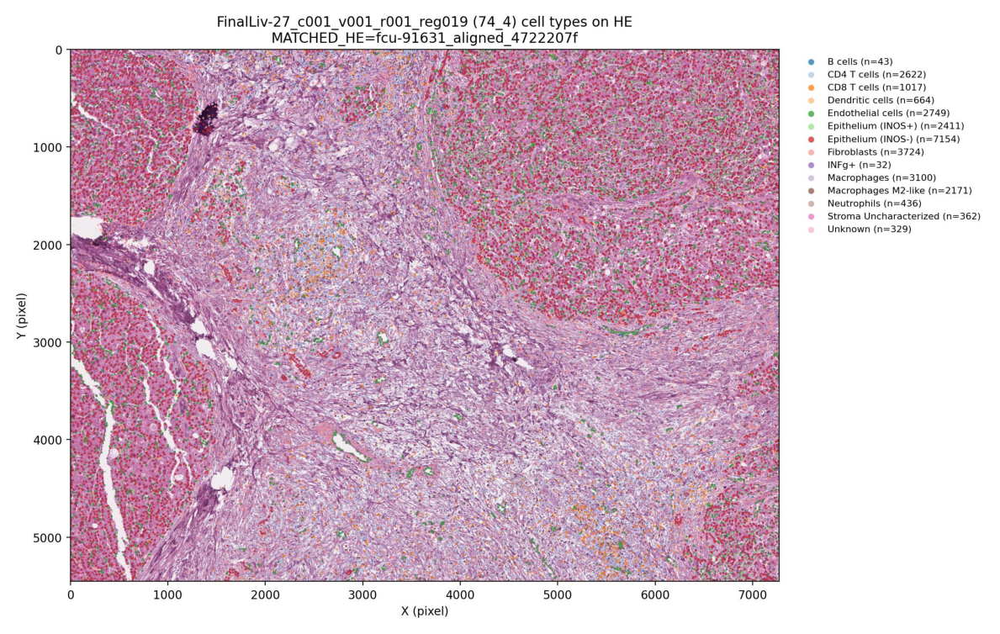

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/fcu-91631_aligned_1e3c06f5/figures/FinalLiv-27_c001_v001_r001_reg020_celltype_on_HE.jpg


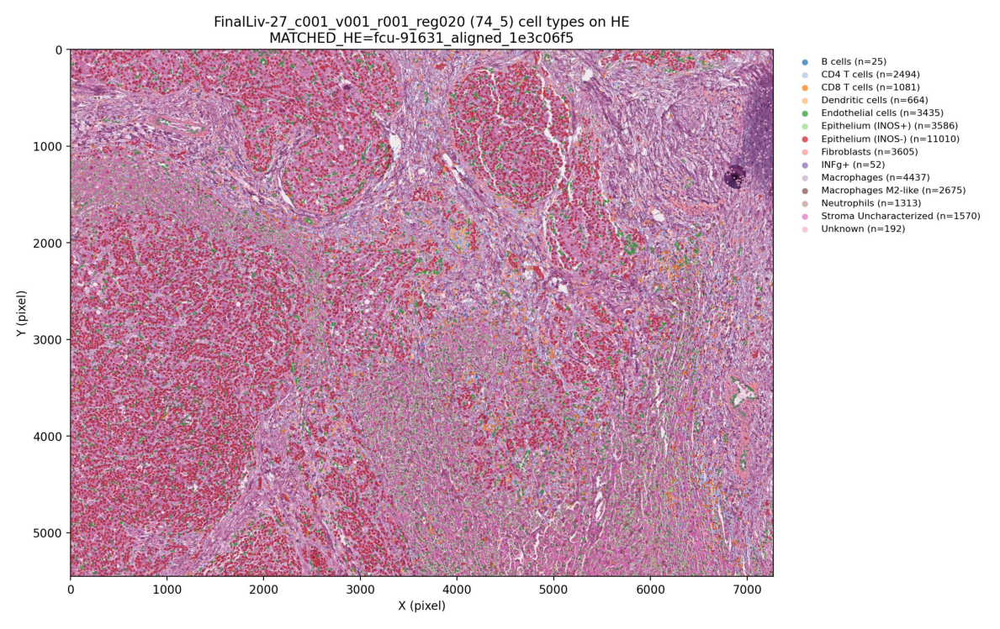

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/xid-87175_aligned_6a382a5d/figures/FinalLiv-27_c001_v001_r001_reg021_celltype_on_HE.jpg


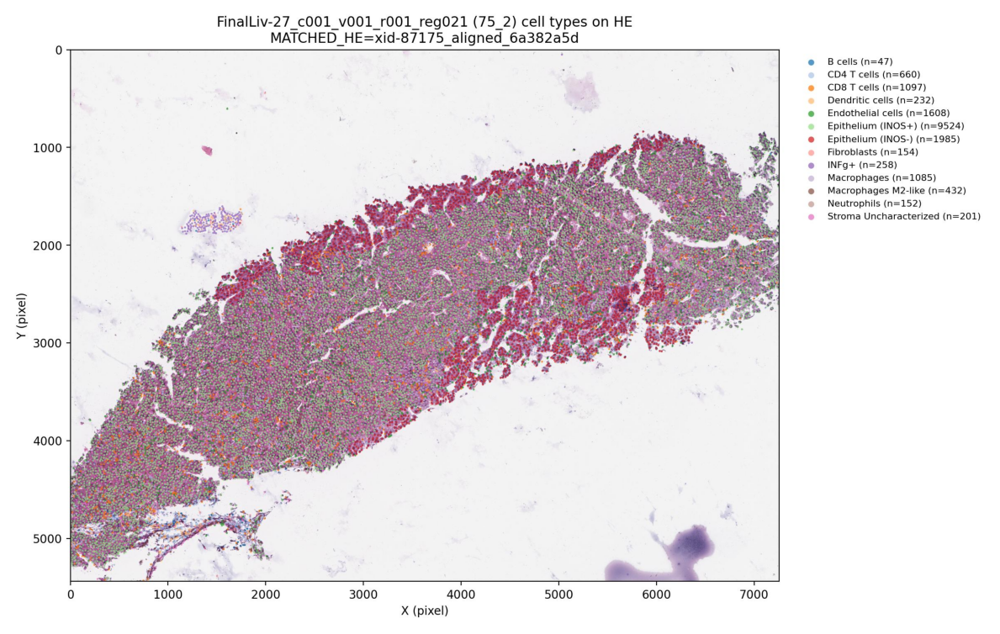

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/xid-87175_aligned_b5f82f61/figures/FinalLiv-27_c001_v001_r001_reg022_celltype_on_HE.jpg


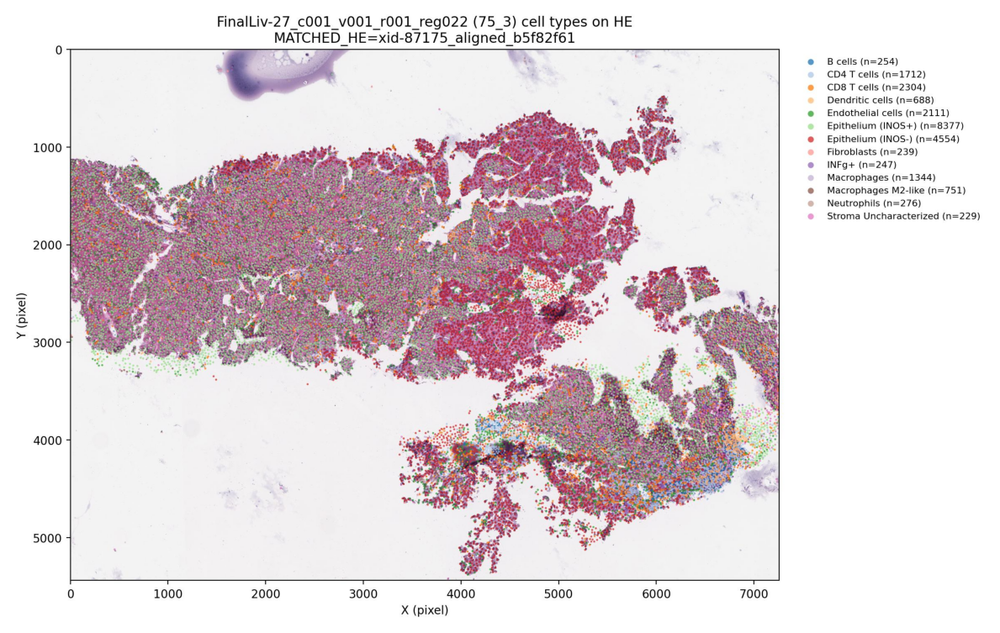

SKIP (no JPG): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/xid-87175_aligned_f82fb393/figures/FinalLiv-27_c001_v001_r001_reg023_celltype_on_HE.jpg
Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/xid-87175_aligned_c06f7c7e/figures/FinalLiv-27_c001_v001_r001_reg024_celltype_on_HE.jpg


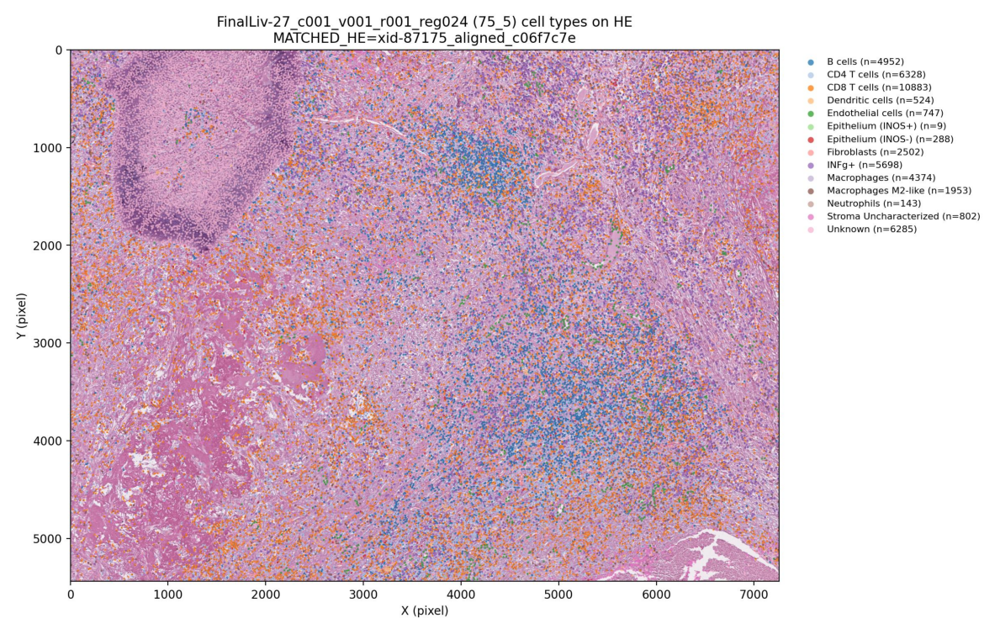

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/lvr-76315_aligned_5c66cd56/figures/FinalLiv-27_c002_v001_r001_reg005_celltype_on_HE.jpg


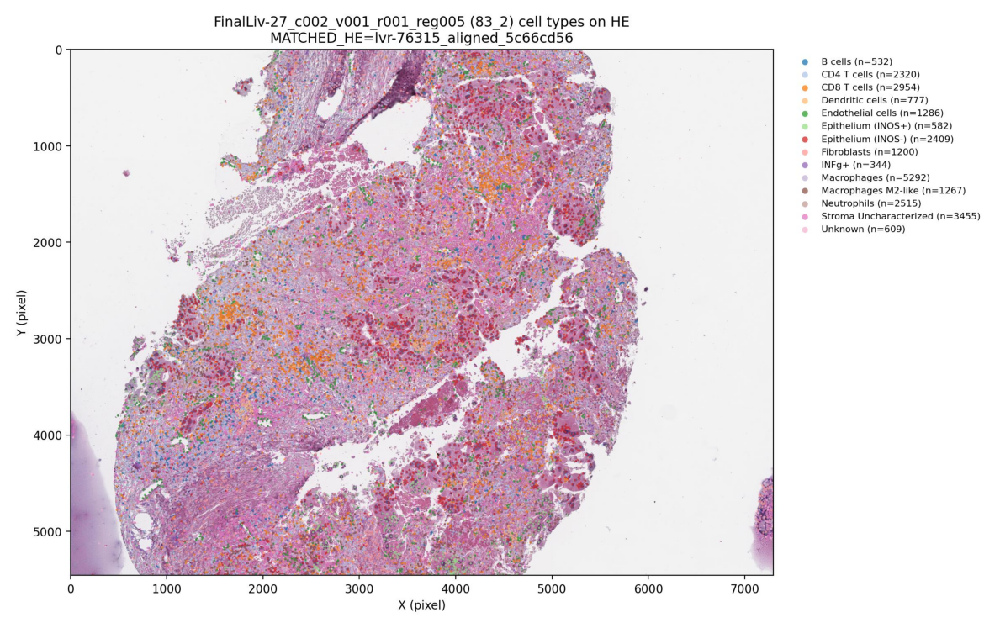

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/lvr-76315_aligned_7c2e2f0a/figures/FinalLiv-27_c002_v001_r001_reg006_celltype_on_HE.jpg


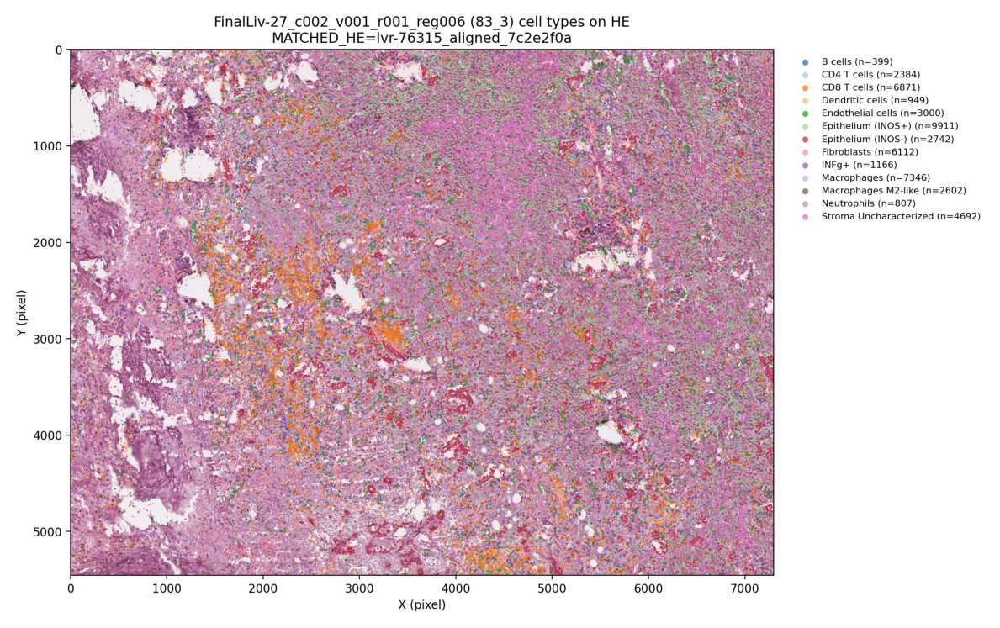

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/lvr-76315_aligned_9c96ea90/figures/FinalLiv-27_c002_v001_r001_reg007_celltype_on_HE.jpg


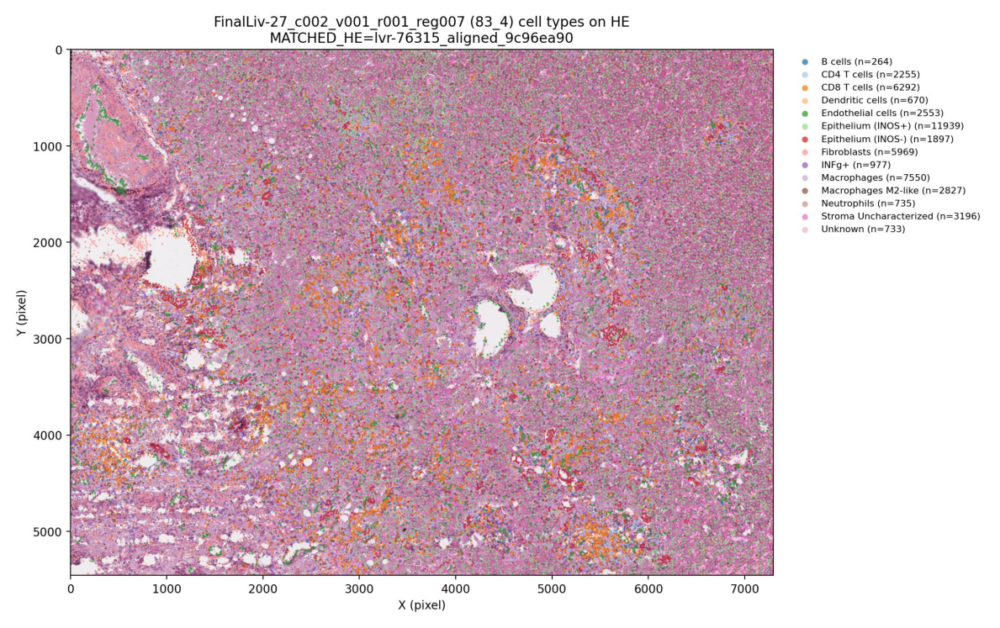

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/ovn-46364_aligned_9a3f8b10/figures/FinalLiv-27_c002_v001_r001_reg008_celltype_on_HE.jpg


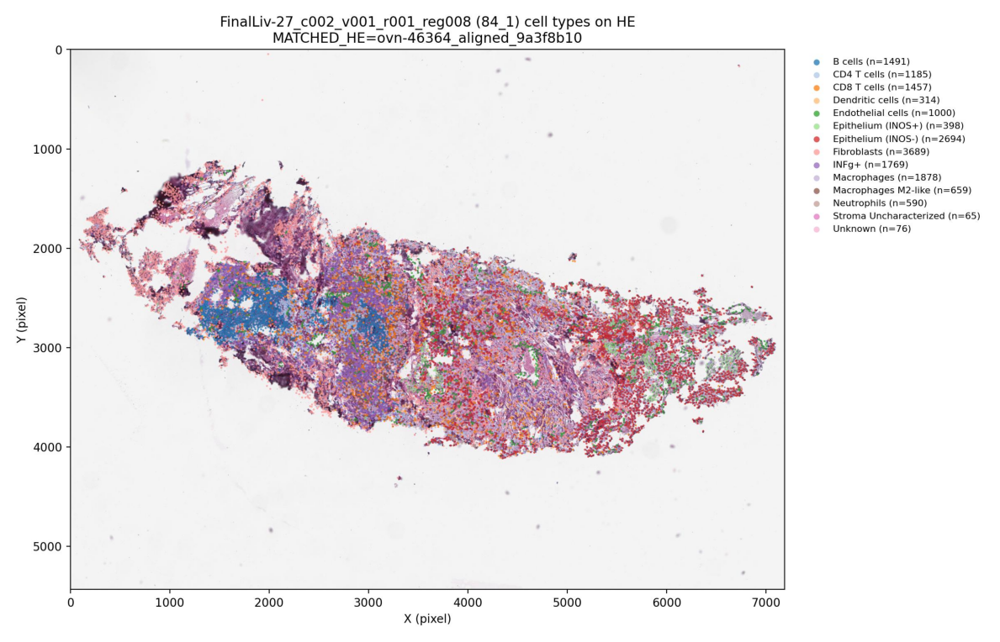

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/ovn-46364_aligned_4db9e0ee/figures/FinalLiv-27_c002_v001_r001_reg009_celltype_on_HE.jpg


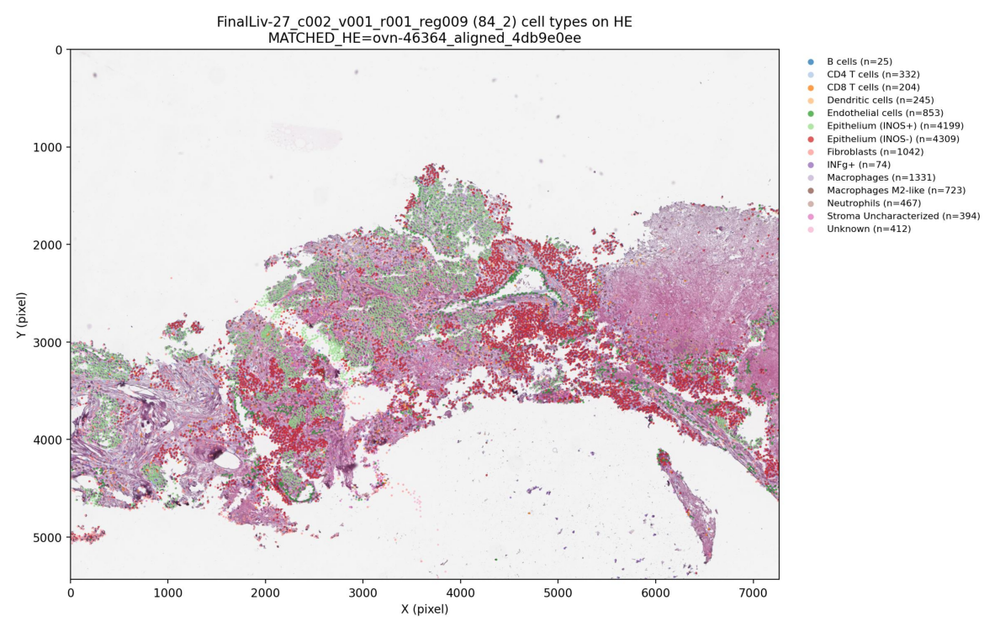

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/ovn-46364_aligned_cb1fb28a/figures/FinalLiv-27_c002_v001_r001_reg010_celltype_on_HE.jpg


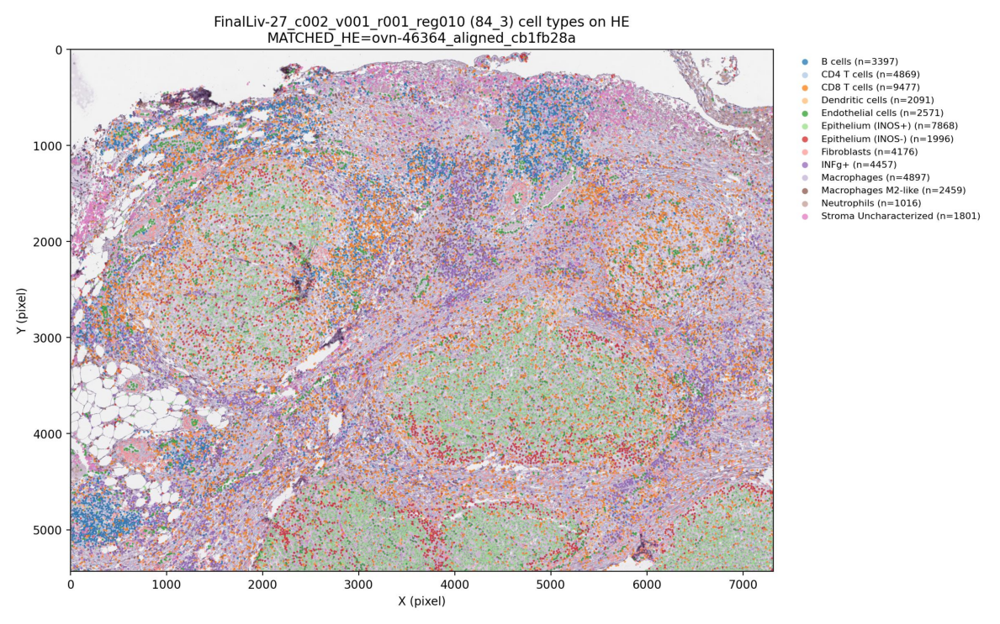

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/ovn-46364_aligned_4fc438fb/figures/FinalLiv-27_c002_v001_r001_reg011_celltype_on_HE.jpg


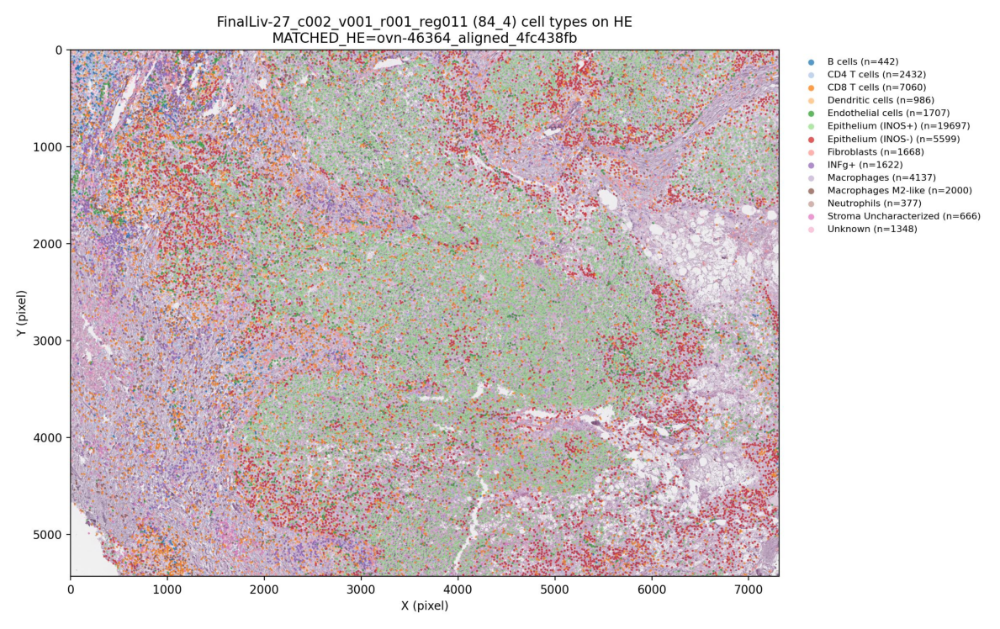

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/uzr-70552_aligned_aab73d87/figures/FinalLiv-27_c002_v001_r001_reg012_celltype_on_HE.jpg


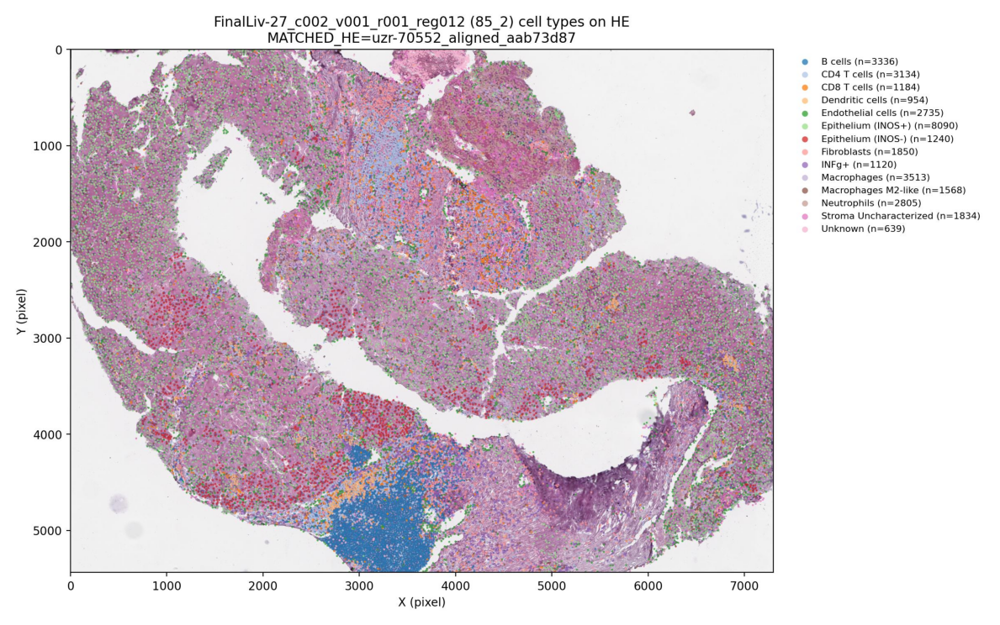

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/uzr-70552_aligned_28fccc90/figures/FinalLiv-27_c002_v001_r001_reg013_celltype_on_HE.jpg


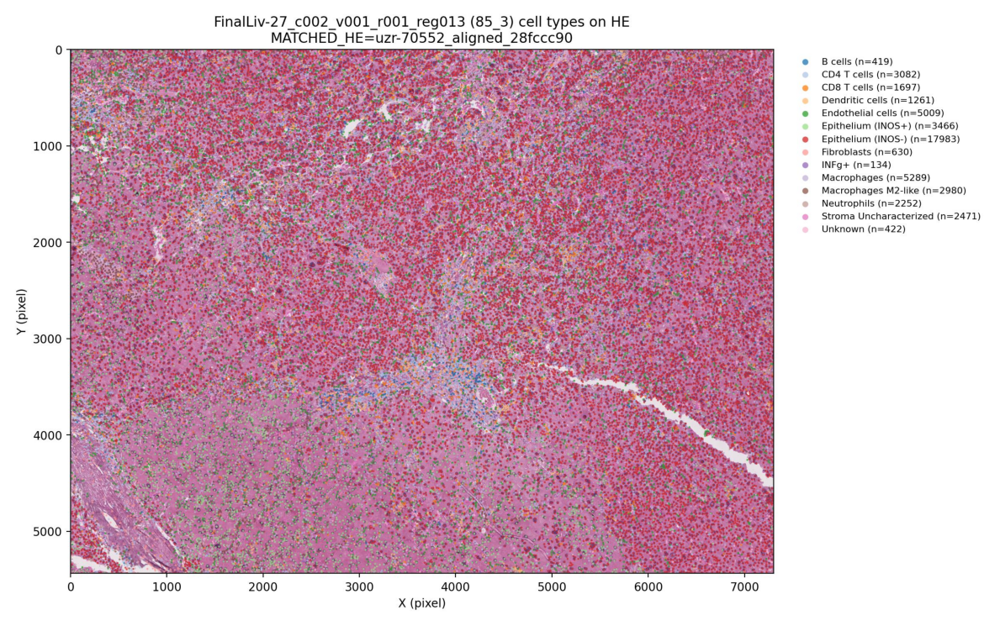

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/uzr-70552_aligned_0a3ce40a/figures/FinalLiv-27_c002_v001_r001_reg014_celltype_on_HE.jpg


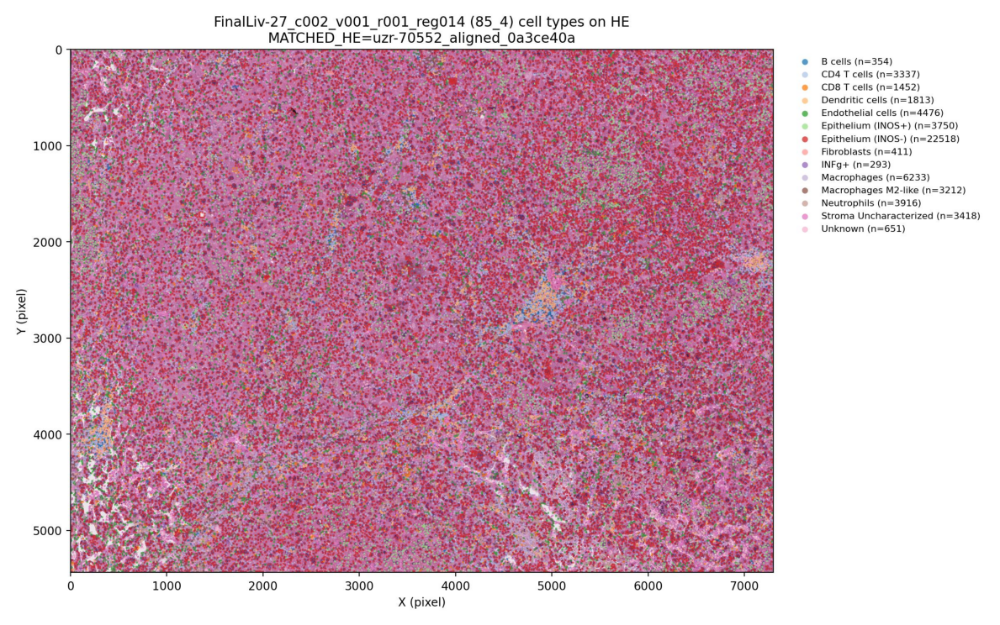

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/tai-49708_aligned_4a16a5bc/figures/FinalLiv-27_c002_v001_r001_reg015_celltype_on_HE.jpg


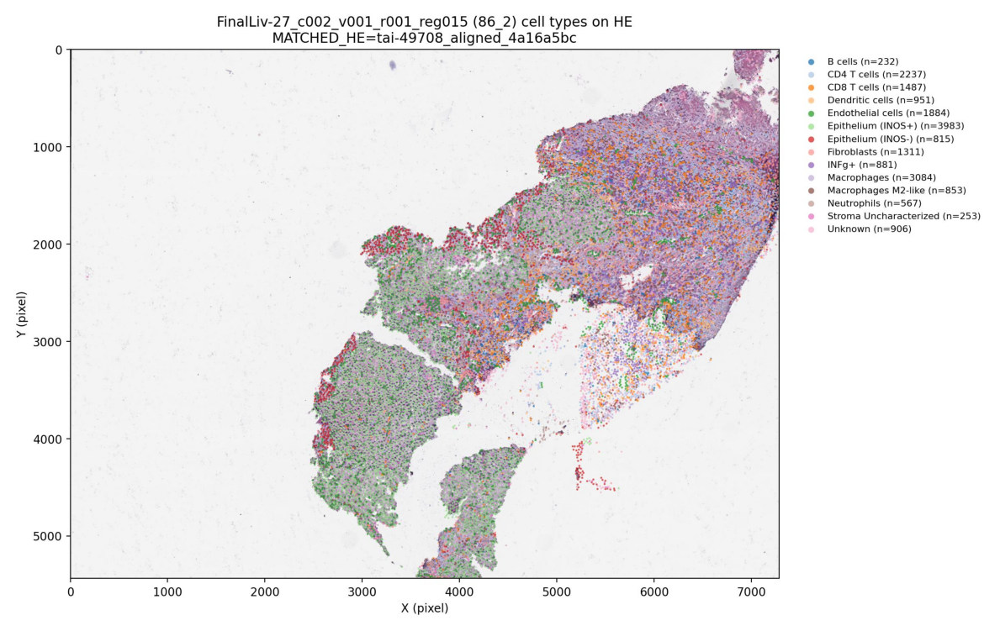

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/tai-49708_aligned_6b614b49/figures/FinalLiv-27_c002_v001_r001_reg016_celltype_on_HE.jpg


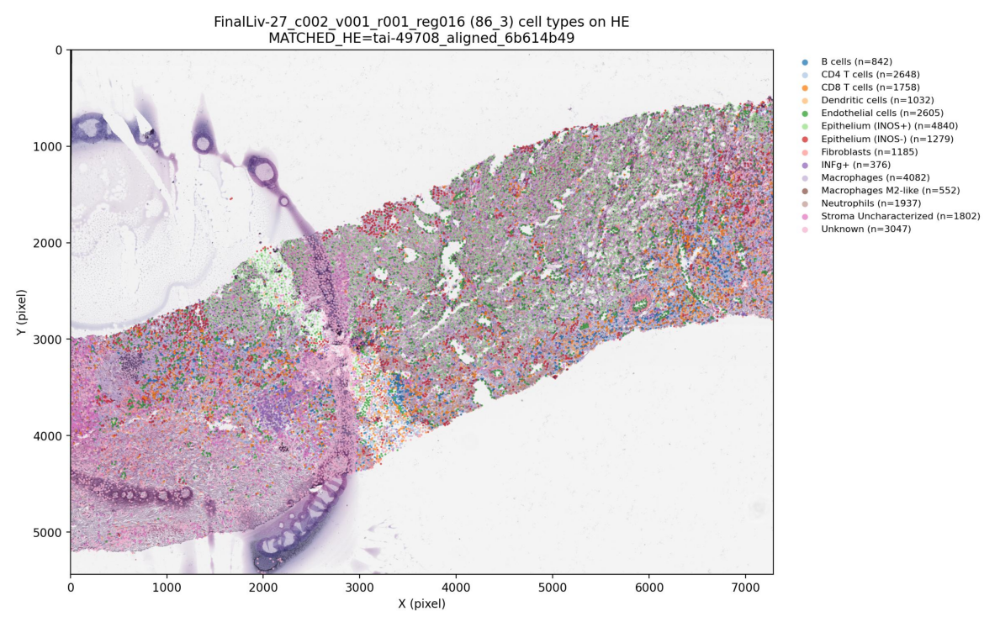

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/tai-49708_aligned_459aad10/figures/FinalLiv-27_c002_v001_r001_reg017_celltype_on_HE.jpg


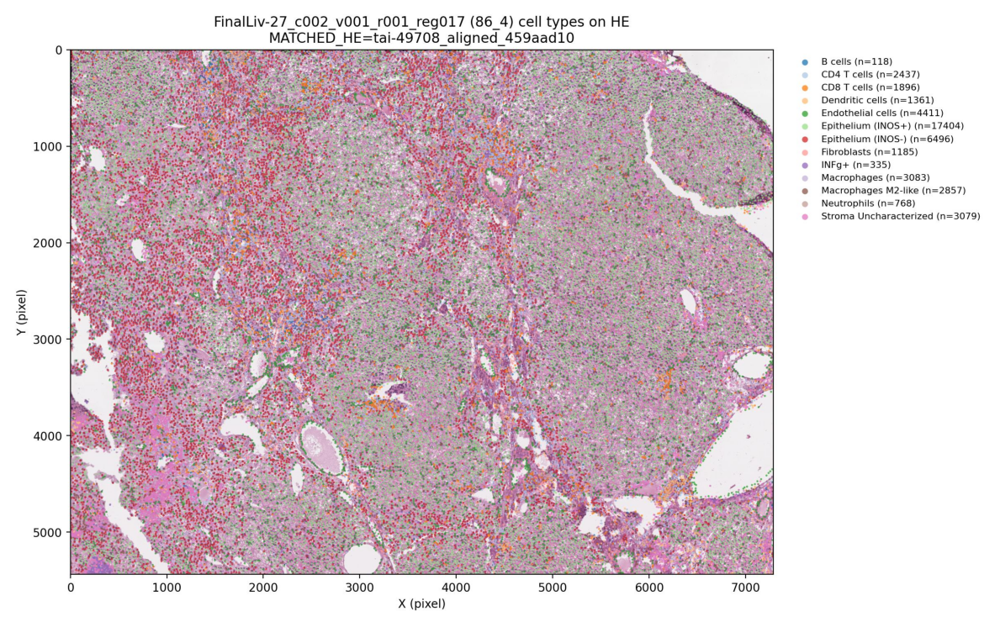

Displayed (existing): /home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/tai-49708_aligned_3652c629/figures/FinalLiv-27_c002_v001_r001_reg018_celltype_on_HE.jpg


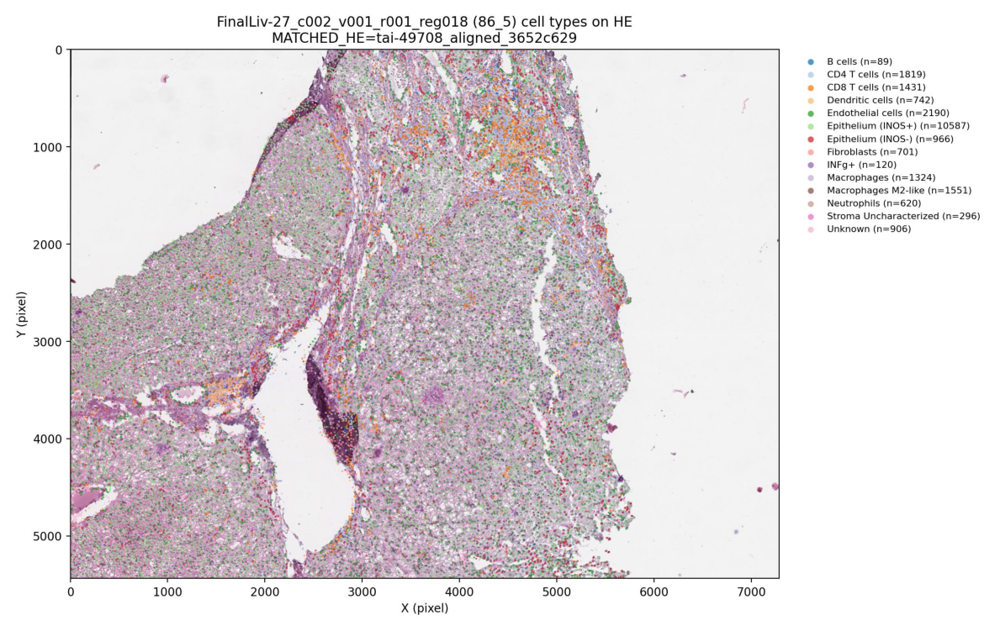

Displayed 36 JPG(s)


[PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_0d535a74/figures/FinalLiv-27_c001_v001_r001_reg001_celltype_on_HE.jpg'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_8ded610e/figures/FinalLiv-27_c001_v001_r001_reg002_celltype_on_HE.jpg'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_a5afeef9/figures/FinalLiv-27_c001_v001_r001_reg003_celltype_on_HE.jpg'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/awy-98938_aligned_59f27598/figures/FinalLiv-27_c001_v001_r001_reg004_celltype_on_HE.jpg'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/Michael_data_transfer/s4769/HE/nwn-95916_aligned_d1ec33a2/figures/FinalLiv-27_c001_v001_r001_reg005_celltype_on_HE.jpg'),
 PosixPath('/home/lingyu/ssd2/Python/Collaborate/esccAI/data/HCC/

In [9]:
## Preview saved cell-type JPGs
## plot_all_acq_spatial loops over cells_by_acq only — currently 1 region if ACQ_IDS_ALSO_VIEW=[]
# plot_all_acq_spatial(cells_by_acq, alignment_df, base_dir=CODEX_hcc_dir, show=True, reuse_existing=True)

export_he_celltype_png("uzr-70552_aligned_aab73d87", alignment_df, base_dir=CODEX_hcc_dir, dpi=300, show=True, formats=("png", "pdf"))

# Preview ALL saved JPGs from alignment_df (38 regions; skips missing JPG)
preview_aligned_celltype_jpgs(alignment_df, base_dir=CODEX_hcc_dir, show=True)

## Or preview selected regions only:
# preview_aligned_celltype_jpgs(
#     alignment_df, base_dir=CODEX_hcc_dir,
#     acq_ids=['FinalLiv-27_c001_v001_r001_reg005', 'FinalLiv-27_c001_v001_r001_reg006'],
# )

## TLS score

## Load StarDist results

In [4]:
select4_dir = f'{path}Hist2Pheno/data/Xemium/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4'
dataset_select = 'VUHD113'   # 'VUILD107MA'

import pandas as pd
def load_star_dist_data(select4_dir, dataset_select='VUHD113'):
    """Read StarDist CSV from Complete_Cases_Select4/{sample}/."""
    star_dist_path = f'{select4_dir}/{dataset_select}/{dataset_select}_Float_prob001_nms_03.csv'
    star_dist_df = pd.read_csv(star_dist_path)
    star_dist_df['sample'] = dataset_select
    print(f'[{dataset_select}] StarDist CSV: {star_dist_path}')
    print(f'[{dataset_select}] cell number of star_dist:', star_dist_df.shape)
    return star_dist_df

DATASETS = ['VUHD113', 'VUILD107MA', 'VUILD102LA', 'VUILD96LA']
star_dist_all = {
    s: load_star_dist_data(select4_dir, dataset_select=s)
    for s in DATASETS
}
star_dist_ = star_dist_all[dataset_select]

[VUHD113] StarDist CSV: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUHD113/VUHD113_Float_prob001_nms_03.csv
[VUHD113] cell number of star_dist: (23745, 4)
[VUILD107MA] StarDist CSV: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUILD107MA/VUILD107MA_Float_prob001_nms_03.csv
[VUILD107MA] cell number of star_dist: (105857, 4)
[VUILD102LA] StarDist CSV: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUILD102LA/VUILD102LA_Float_prob001_nms_03.csv
[VUILD102LA] cell number of star_dist: (60484, 4)
[VUILD96LA] StarDist CSV: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUILD96LA/VUILD96LA_Float_prob001_nms_03.csv
[VUILD96LA] cell number of star_dist: (8

In [5]:
star_dist_ = load_star_dist_data(select4_dir, dataset_select=dataset_select)
star_dist_.head()

[VUHD113] StarDist CSV: /home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUHD113/VUHD113_Float_prob001_nms_03.csv
[VUHD113] cell number of star_dist: (23745, 4)


,centroid_x,centroid_y,probability,sample
0,3678.293251,3560.173920,0.886976,VUHD113
1,3371.622482,3423.181580,0.883140,VUHD113
2,412.258600,795.808817,0.878218,VUHD113
3,3705.858780,3700.159309,0.874990,VUHD113
4,352.317239,705.626997,0.867907,VUHD113


### HE - StarDist

In [7]:
## Load stardist coords (Complete_Cases_Select4/{sample}/)
therapy_data = 'VUHD113'
star_coords_path = f'{select4_dir}/{therapy_data}/{therapy_data}_Float_prob001_nms_03.csv'
star_coords = pd.read_csv(star_coords_path)
print(star_coords_path)
print(star_coords.shape)
star_coords.head()

/home/lingyu/ssd2/Python/Collaborate/esccAI/data/Xemiun/weiqin/SpatialPF-NGenetics/Spatial-PF-Processed/Data/Complete_Cases_Select4/VUHD113/VUHD113_Float_prob001_nms_03.csv
(23745, 3)


,centroid_x,centroid_y,probability
0,3678.293251,3560.173920,0.886976
1,3371.622482,3423.181580,0.883140
2,412.258600,795.808817,0.878218
3,3705.858780,3700.159309,0.874990
4,352.317239,705.626997,0.867907
